Інсталюємо бібліотеку

In [ ]:
!pip install numpy==1.21.1 pandas==2.2.2 tabulate==0.9 tensorflow==2.18.0 numba==0.60.0 --force-reinstall
!pip install fuzzy-c-means==1.7.2 --force-reinstall
import os
os._exit(00)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 46.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of pandas to determine which version is compatible with other requirements. This could take a while.
ERROR: Cannot install numpy==1.21.1 and pandas==2.2.2 because these package versions have conflicting dependencies.

The conflict is caused by:
    The user requested numpy==1.21.1
    pandas 2.2.2 depends on numpy>=1.23.2; python_version == "3.11"

To fix this you could try to:
1. loosen the range of package versions you've specified
2. remove package versions to allow pip to attempt to solve the dependency conflict

ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts
  Using cached fuzzy_c_means-1.7.2-py3-none-any.whl.metadata (4.7 kB)
  Using cac

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
from google.colab import files
files.upload()

Saving dummy_data.csv to dummy_data.csv


{'dummy_data.csv': b'age,gender,time_spent,platform,interests,location,demographics,profession,income,indebt,isHomeOwner,Owns_Car\r\n56,male,3,Instagram,Sports,United Kingdom,Urban,Software Engineer,19774,True,False,False\r\n46,female,2,Facebook,Travel,United Kingdom,Urban,Student,10564,True,True,True\r\n32,male,8,Instagram,Sports,Australia,Sub_Urban,Marketer Manager,13258,False,False,False\r\n60,non-binary,5,Instagram,Travel,United Kingdom,Urban,Student,12500,False,True,False\r\n25,male,1,Instagram,Lifestlye,Australia,Urban,Software Engineer,14566,False,True,True\r\n38,male,3,Facebook,Travel,United States,Urban,Marketer Manager,19179,True,True,True\r\n56,male,8,YouTube,Sports,United States,Urban,Student,16881,True,True,True\r\n36,male,4,Instagram,Sports,Australia,Urban,Marketer Manager,13636,True,False,True\r\n40,non-binary,7,YouTube,Lifestlye,Australia,Sub_Urban,Marketer Manager,16030,False,False,True\r\n28,non-binary,2,Instagram,Sports,Australia,Sub_Urban,Marketer Manager,10223,True

Використаємо датасет Average Time Spent By A User On Social Media, спробуємо розділити (кластеризувати) користувачів за 3 ознаками

In [3]:
import pandas as pd
df = pd.read_csv('dummy_data.csv')
df

,age,gender,time_spent,platform,interests,location,demographics,profession,income,indebt,isHomeOwner,Owns_Car
0,56,male,3,Instagram,Sports,United Kingdom,Urban,Software Engineer,19774,True,False,False
1,46,female,2,Facebook,Travel,United Kingdom,Urban,Student,10564,True,True,True
2,32,male,8,Instagram,Sports,Australia,Sub_Urban,Marketer Manager,13258,False,False,False
3,60,non-binary,5,Instagram,Travel,United Kingdom,Urban,Student,12500,False,True,False
4,25,male,1,Instagram,Lifestlye,Australia,Urban,Software Engineer,14566,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
995,22,female,8,Instagram,Lifestlye,United Kingdom,Rural,Marketer Manager,18536,False,True,False
996,40,non-binary,6,YouTube,Travel,United Kingdom,Rural,Software Engineer,12711,True,False,False
997,27,non-binary,5,YouTube,Travel,United Kingdom,Rural,Student,17595,True,False,True
998,61,female,4,YouTube,Sports,Australia,Sub_Urban,Marketer Manager,16273,True,True,False


In [4]:
df.describe()

,age,time_spent,income
count,1000.000000,1000.000000,1000.000000
mean,40.986000,5.029000,15014.823000
std,13.497852,2.537834,2958.628221
min,18.000000,1.000000,10012.000000
25%,29.000000,3.000000,12402.250000
50%,42.000000,5.000000,14904.500000
75%,52.000000,7.000000,17674.250000
max,64.000000,9.000000,19980.000000


In [5]:
df.isnull().sum()

,0
age,0
gender,0
time_spent,0
platform,0
interests,0
location,0
demographics,0
profession,0
income,0
indebt,0


In [6]:
df.shape

(1000, 12)

Всі ознаки не корелюють одна з одною

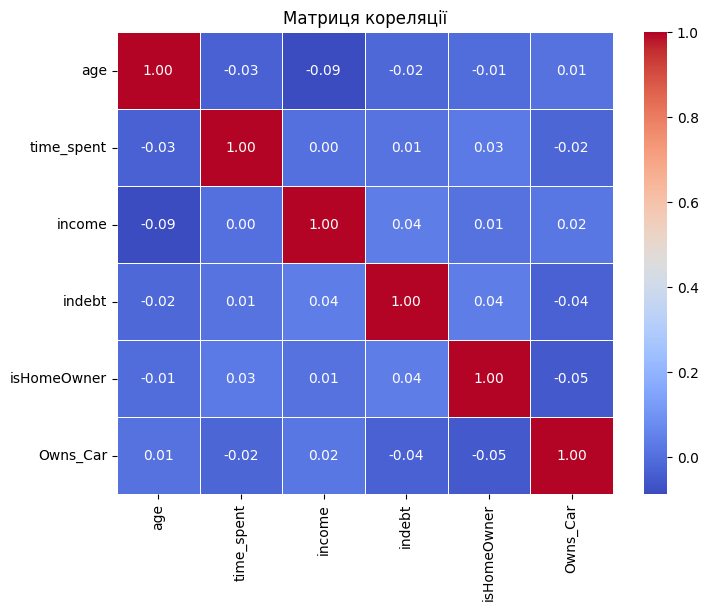

In [8]:
import seaborn as sns
# Обчислимо кореляцію лише для числових змінних
corr_matrix = df.corr(numeric_only=True)

# Побудова теплокарти (heatmap)
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Матриця кореляції")
plt.show()

Обираємо три некорельовані ознаки із нормальним законом розподілу

<Axes: xlabel='time_spent', ylabel='Density'>

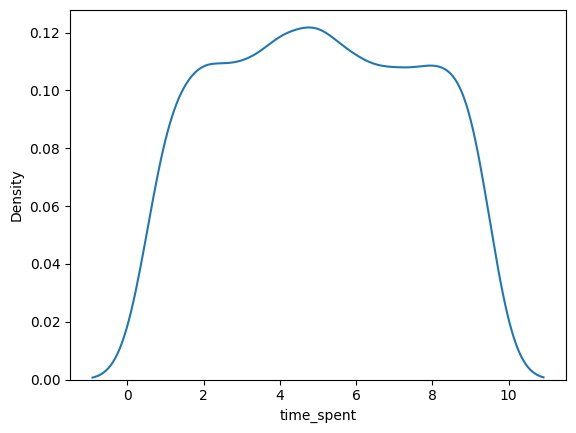

In [9]:
sns.kdeplot(df['time_spent'])

<Axes: xlabel='income', ylabel='Density'>

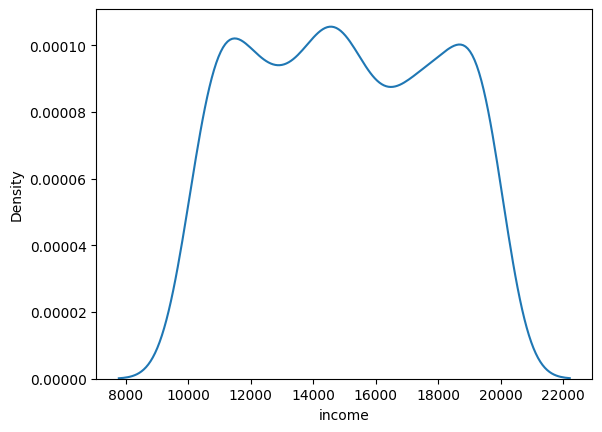

In [10]:
sns.kdeplot(df['income'])

<Axes: xlabel='age', ylabel='Density'>

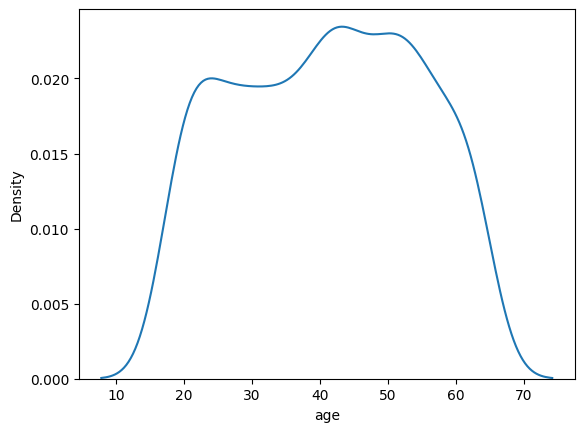

In [11]:
sns.kdeplot(df['age'])

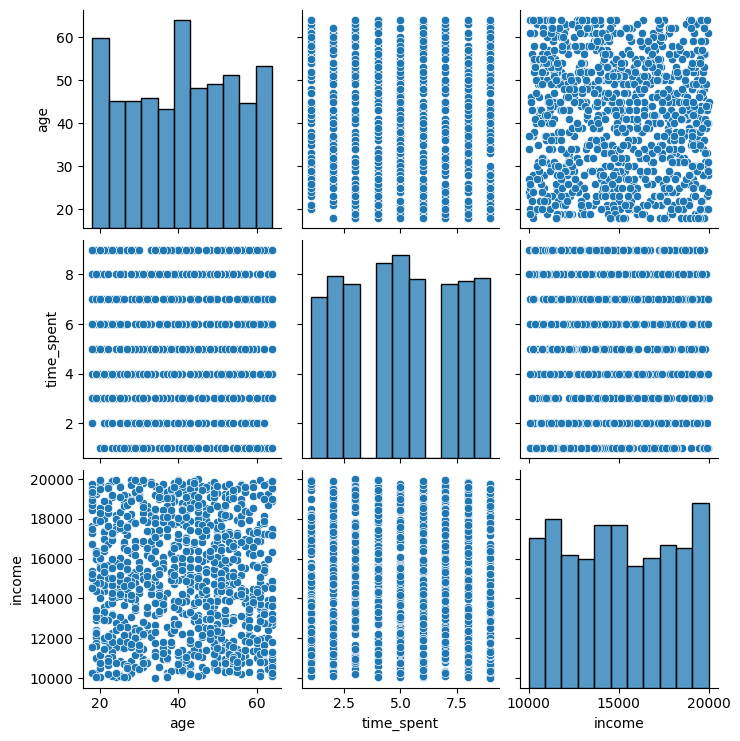

In [12]:
sns.pairplot(df[['age', 'time_spent','income']])

Спостереження:
Усі користувачі розбиті рівномірно, всі дані розкидані рівномірно й не видно чіткої залежності, можливо кластерний аналіз покаже якийсь зв'язок

In [13]:
from sklearn.preprocessing import StandardScaler

# Select columns for clustering
cols = ['age', 'time_spent','income']
# Filter the columns and convert into matrix
df_not_scaled = df[cols].to_numpy()
# Min-max scaler
scaler = StandardScaler()
# Transform the data
scaled = scaler.fit_transform(df_not_scaled)

Визначимо найкращу кількість кластерів.
Оцінка силуету має бути вищою, для кращого розподілу між кластерами

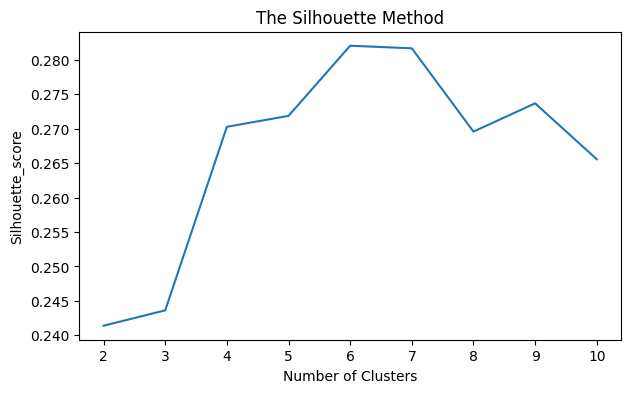

In [14]:
from fcmeans import FCM

## Clustering Metrics
from sklearn.metrics import  silhouette_score
wcss=[]
for i in range(2,11):
    fcm = FCM(n_clusters=i, random_state=0)
    # outputs
    fcm.fit(scaled)
    fcm_labels = fcm.predict(scaled)
    err1=silhouette_score(scaled, fcm_labels)
    wcss.append(err1)
import matplotlib.pyplot as plt
plt.figure(figsize=(7,4))
plt.plot(range(2,11),wcss)
plt.title('The Silhouette Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette_score')
plt.show()

Значення оцінки Девіса-Болдіна мають бути ближчими до нуля

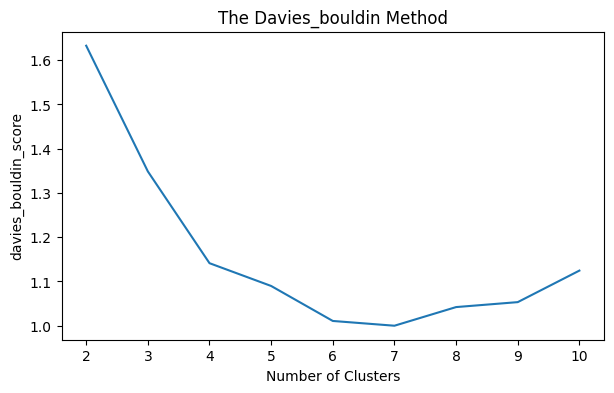

In [15]:
from sklearn.metrics import davies_bouldin_score
wcss=[]
for i in range(2,11):
    fcm = FCM(n_clusters=i, random_state=0)
    # outputs
    fcm.fit(scaled)
    fcm_labels = fcm.predict(scaled)
    err1=davies_bouldin_score (scaled, fcm_labels)
    wcss.append(err1)
plt.figure(figsize=(7,4))
plt.plot(range(2,11),wcss)
plt.title('The Davies_bouldin Method')
plt.xlabel('Number of Clusters')
plt.ylabel('davies_bouldin_score')
plt.show()

Більше значення Індексу Калінскі-Харабаса визначає кращий розподіл

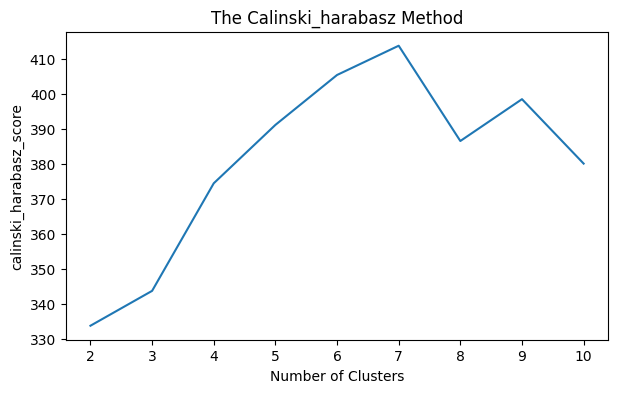

In [16]:
from sklearn.metrics import calinski_harabasz_score
wcss=[]
for i in range(2,11):
    fcm = FCM(n_clusters=i, random_state=0)
    # outputs
    fcm.fit(scaled)
    fcm_labels = fcm.predict(scaled)
    err1=calinski_harabasz_score (scaled, fcm_labels)
    wcss.append(err1)
plt.figure(figsize=(7,4))
plt.plot(range(2,11),wcss)
plt.title('The Calinski_harabasz Method')
plt.xlabel('Number of Clusters')
plt.ylabel('calinski_harabasz_score')
plt.show()

Нечіткий коефіцієнт розподілу (FPC) та ентропія розподілу FPC визначається в діапазоні від 0 до 1, де 1 є найкращим. Це показник, який показує, наскільки точно дані описує певна модель. Коли FPC максимізовано, а ентропія мінімізована, то дані описуються найкраще.

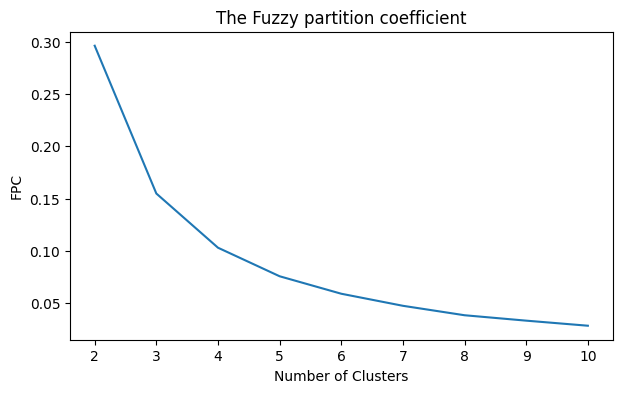

In [17]:
wcss=[]
for i in range(2,11):
    fcm = FCM(n_clusters=i, random_state=0)
    # outputs
    fcm.fit(scaled)
    fcm_labels = fcm.predict(scaled)
    wcss.append(fcm.partition_coefficient)
plt.figure(figsize=(7,4))
plt.plot(range(2,11),wcss)
plt.title('The Fuzzy partition coefficient')
plt.xlabel('Number of Clusters')
plt.ylabel('FPC')
plt.show()

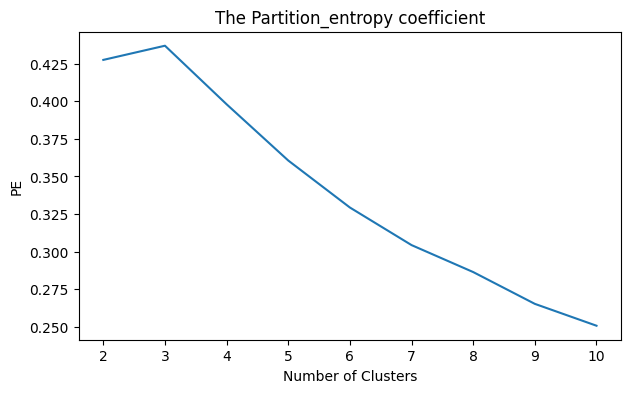

In [18]:
wcss=[]
for i in range(2,11):
    fcm = FCM(n_clusters=i, random_state=0)
    # outputs
    fcm.fit(scaled)
    fcm_labels = fcm.predict(scaled)
    wcss.append(fcm.partition_entropy_coefficient)
plt.figure(figsize=(7,4))
plt.plot(range(2,11),wcss)
plt.title('The Partition_entropy coefficient')
plt.xlabel('Number of Clusters')
plt.ylabel('PE')
plt.show()

Дані показники не є інформативними для даної моделі.
Методи Силуету, Девіса-Болдіна та Калінскі-Харабаса вказують на те що оптимальна кількість кластерів повинна бути **7**

Оскільки цільові ознаки не мають нормального розподілу то найкраще використовувати нечітку кластеризацію

**Нечітка кластеризація**

In [19]:
fcm = FCM(n_clusters=7, random_state=0)
fcm.fit(scaled)
fcm_labels = fcm.predict(scaled)
# outputs
fcm_centers = fcm.centers
fcm_labels = fcm.predict(scaled)
df['Fuzzy_cluster'] = fcm_labels

In [20]:
df

,age,gender,time_spent,platform,interests,location,demographics,profession,income,indebt,isHomeOwner,Owns_Car,Fuzzy_cluster
0,56,male,3,Instagram,Sports,United Kingdom,Urban,Software Engineer,19774,True,False,False,5
1,46,female,2,Facebook,Travel,United Kingdom,Urban,Student,10564,True,True,True,2
2,32,male,8,Instagram,Sports,Australia,Sub_Urban,Marketer Manager,13258,False,False,False,0
3,60,non-binary,5,Instagram,Travel,United Kingdom,Urban,Student,12500,False,True,False,2
4,25,male,1,Instagram,Lifestlye,Australia,Urban,Software Engineer,14566,False,True,True,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,22,female,8,Instagram,Lifestlye,United Kingdom,Rural,Marketer Manager,18536,False,True,False,1
996,40,non-binary,6,YouTube,Travel,United Kingdom,Rural,Software Engineer,12711,True,False,False,6
997,27,non-binary,5,YouTube,Travel,United Kingdom,Rural,Student,17595,True,False,True,3
998,61,female,4,YouTube,Sports,Australia,Sub_Urban,Marketer Manager,16273,True,True,False,5


**М`яка кластеризація**

In [21]:
soft_labels = fcm.soft_predict(scaled)
soft_labels

array([[0.04576739, 0.11757143, 0.08116965, ..., 0.05768931, 0.52069279,
        0.05583375],
       [0.0561715 , 0.03811822, 0.54354558, ..., 0.15203186, 0.07894513,
        0.08133506],
       [0.77012294, 0.04686237, 0.02483312, ..., 0.04398607, 0.02025367,
        0.06667261],
       ...,
       [0.08814418, 0.08995841, 0.0305789 , ..., 0.0828877 , 0.05436546,
        0.0298652 ],
       [0.041697  , 0.08965729, 0.14871486, ..., 0.05144742, 0.51898879,
        0.08926282],
       [0.43076639, 0.14920784, 0.04721052, ..., 0.10814226, 0.05602291,
        0.0711612 ]])

Вивід центроїдів

In [22]:
print(fcm_centers)

[[-0.93339554  0.88205646 -0.39458618]
 [ 0.1738859   0.9326194   0.96815902]
 [ 0.79018662 -0.79117447 -0.8637215 ]
 [-0.81892796 -0.53605612  1.00785696]
 [-0.87080164 -0.66461912 -0.5812692 ]
 [ 0.79187486 -0.74230805  0.6802257 ]
 [ 0.78832228  0.90325491 -0.8476579 ]]


Побудова 3d графіка

In [23]:
import plotly.graph_objs as go

x = df[['age', 'time_spent','income']].values
# 3d scatterplot using plotly
Scene = dict(xaxis = dict(title  = 'age -->'),yaxis = dict(title  = 'Time Spent--->'),zaxis = dict(title  = 'Income-->'))

# model.labels_ is nothing but the predicted clusters i.e y_clusters
labels = fcm_labels
trace = go.Scatter3d(x=x[:, 0], y=x[:, 1], z=x[:, 2], mode='markers',marker=dict(color = labels, size= 5, line=dict(color= 'black',width = 10)))
layout = go.Layout(margin=dict(l=0,r=0),scene = Scene,height = 800,width = 800)
data = [trace]
fig = go.Figure(data = data, layout = layout)
fig.show()

Кластеризація вийшла досить не чіткою, можна спробувати або зменшити кількість кластерів, або спробувати інший метод кластеризації

In [24]:
import numpy as np

def entropy(u):
    return -np.sum(u * np.log2(u + 1e-10)) / len(u)

fpc = (fcm.u ** 2).sum() / len(scaled)
ent = entropy(fcm.u)

print(f'FPC: {fpc}')
print(f'Entropy: {ent}')


FPC: 0.33167205432551566
Entropy: 2.1309450044928515


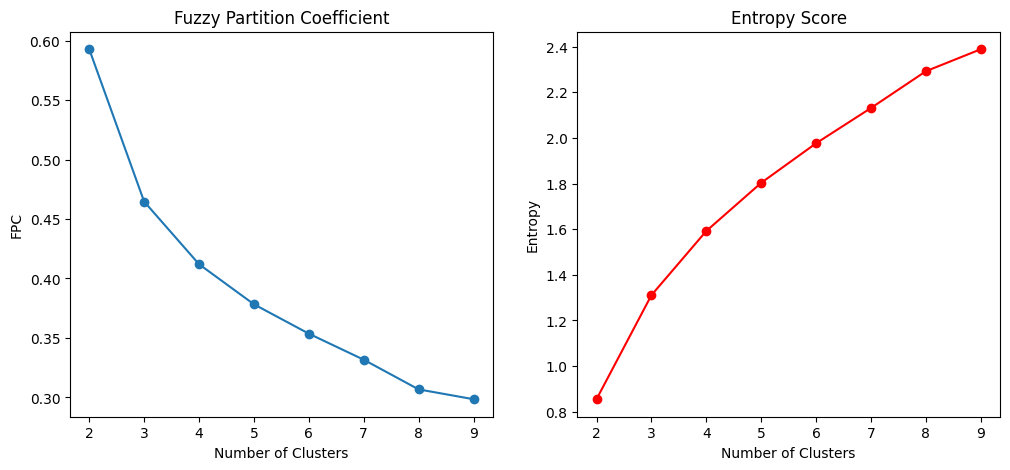

In [25]:
fpc_values = []
entropy_values = []
cluster_range = range(2, 10)

for k in cluster_range:
    fcm = FCM(n_clusters=k, random_state=0)
    fcm.fit(scaled)
    u = fcm.u

    fpc_values.append((u ** 2).sum() / len(scaled))
    entropy_values.append(entropy(u))

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(cluster_range, fpc_values, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('FPC')
plt.title('Fuzzy Partition Coefficient')

plt.subplot(1, 2, 2)
plt.plot(cluster_range, entropy_values, marker='o', color='r')
plt.xlabel('Number of Clusters')
plt.ylabel('Entropy')
plt.title('Entropy Score')

plt.show()
